<a href="https://colab.research.google.com/github/ThirumalReddyPeddi/Play-Store-App-Review-Analysis-Exploratory-Data-Analysis/blob/main/P1_4_7%2C12_Grouped_Bar_Chart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Chart - 7

#####Q).Which app categories contain the highest number of free and paid applications?

In [ ]:
# Chart - 7 visualization code

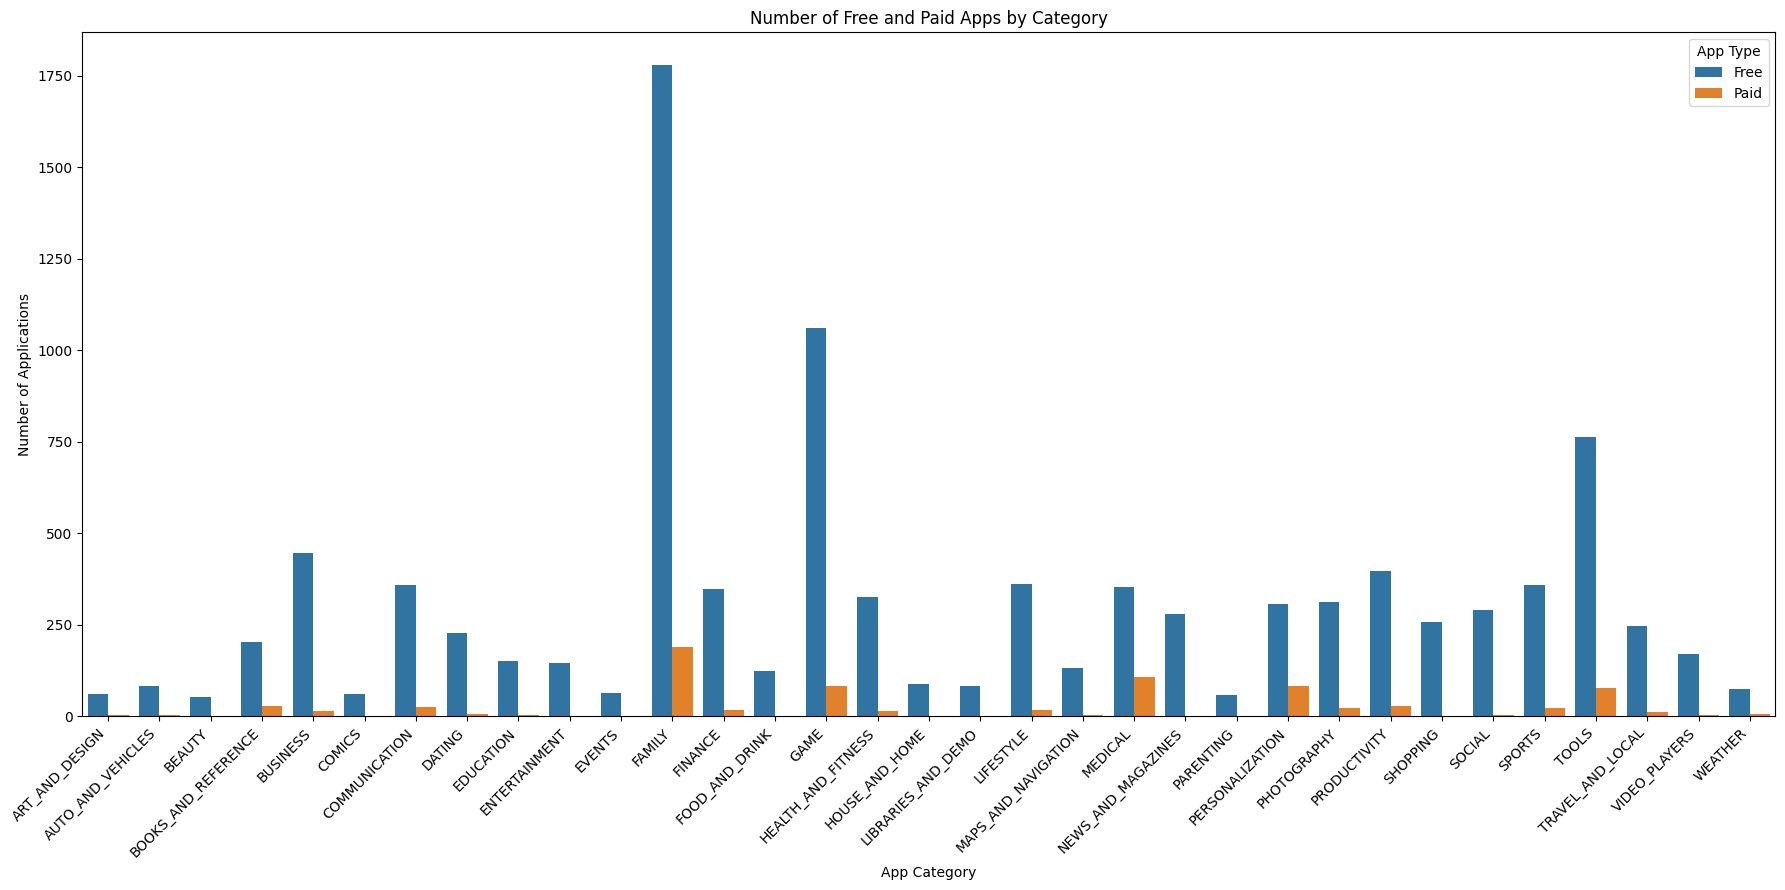

In [ ]:
# A grouped bar chart is useful for comparing the number of free and paid apps in each category.
# It helps identify which categories have the most free apps and which have the most paid apps.

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Remove rows with missing category or app type
type_df = playstore_data.dropna(subset=['Category', 'Type']).copy()

# Count free and paid apps in each category
category_type_counts = (
    type_df.groupby(['Category', 'Type'])
    .size()
    .reset_index(name='App_Count')
)

# Plot grouped bar chart
plt.figure(figsize=(18, 9))

sns.barplot(
    data=category_type_counts,
    x='Category',
    y='App_Count',
    hue='Type'
)

plt.title('Number of Free and Paid Apps by Category')
plt.xlabel('App Category')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.legend(title='App Type')
plt.tight_layout()
plt.show()

In [ ]:
#  Find the categories with the highest counts.


# Compare counts of free and paid apps

category_type_pivot = category_type_counts.pivot(
    index='Category',
    columns='Type',
    values='App_Count'
).fillna(0)


print(category_type_pivot.sort_values('Free', ascending=False).head(5))
print("\n ",category_type_pivot.sort_values('Paid', ascending=False).head(5))

Type            Free   Paid
Category                   
FAMILY        1779.0  190.0
GAME          1061.0   83.0
TOOLS          764.0   77.0
BUSINESS       446.0   14.0
PRODUCTIVITY   396.0   28.0

  Type               Free   Paid
Category                      
FAMILY           1779.0  190.0
MEDICAL           354.0  109.0
GAME             1061.0   83.0
PERSONALIZATION   308.0   82.0
TOOLS             764.0   77.0


###### 1. Why did you pick the specific chart?

A grouped bar chart was selected because it allows us to compare the number of free and paid applications across different categories. Different colors represent each app type, making it easy to identify which categories contain the highest numbers of free and paid apps. &#x20;



###### 2. What is/are the insight(s) found from the chart?

The chart helps identify categories with the highest numbers of free and paid applications. Comparing the bars can reveal whether a category is dominated by free apps or has a relatively larger number of paid apps. &#x20;

The exact leading categories should be identified from the chart or calculated counts. These results help us understand app distribution and pricing patterns across categories.  &#x20;

###### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help developers understand competition and choose suitable pricing strategies. Categories with many free apps may have strong competition for users, while categories with more paid apps may offer opportunities to explore paid features or premium services. &#x20;

However, a high number of free or paid apps does not automatically indicate higher demand or profitability. Categories dominated by free apps may make it difficult for paid apps to attract users, while paid apps may face barriers to adoption because users must pay upfront. Businesses should consider market demand, ratings, installs, and competition before choosing a pricing model. &#x20;


#### Chart - 12

In [ ]:
# Chart - 12 visualization code

#####Q).Which app categories receive the most positive and negative user feedback?

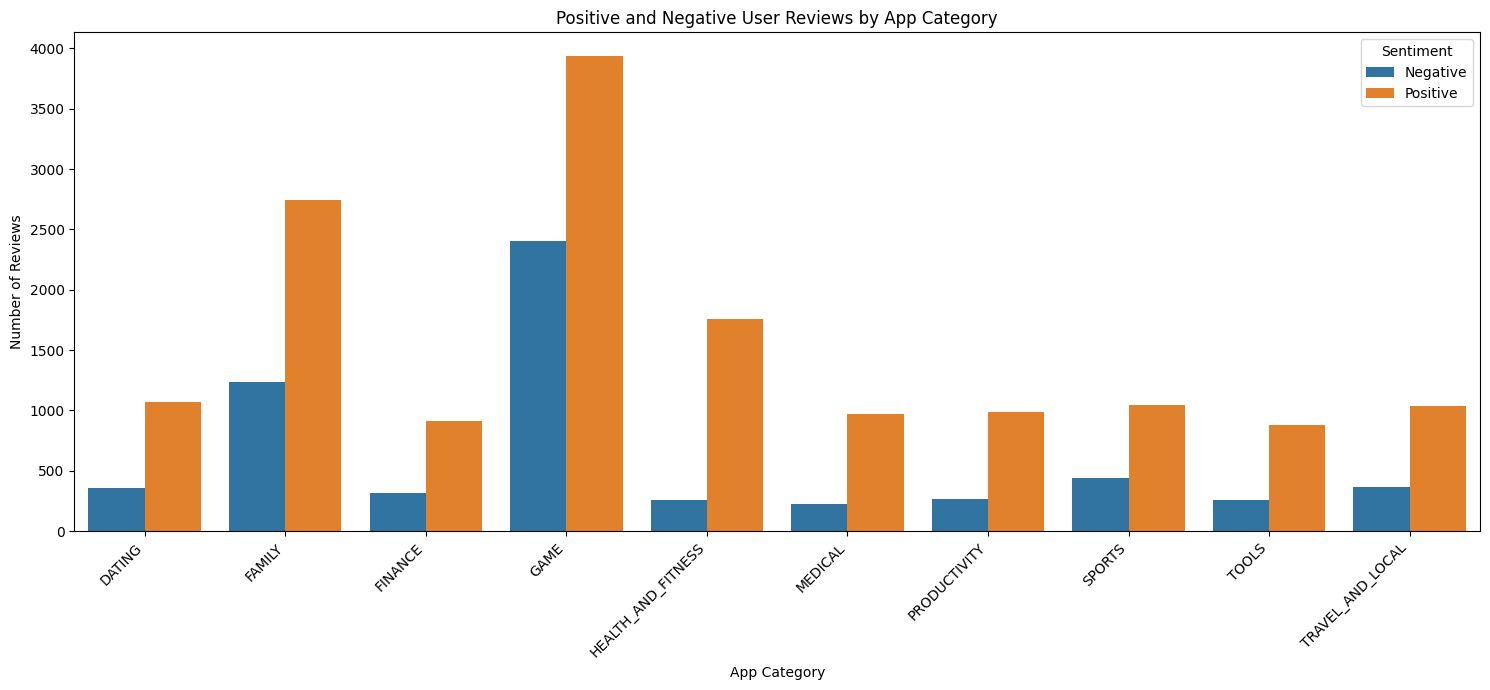

In [ ]:
# We can answer this by combining the Play Store dataset (df, containing app categories) with the User Reviews dataset (df_reviews, containing review sentiments).
# We will count positive and negative reviews for each category and compare the results using a grouped bar chart.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the app category from the Play Store dataset
app_categories = playstore_data[['App', 'Category']].drop_duplicates()

# Combine app categories with user reviews
reviews_with_category = user_reviews_data.merge(
    app_categories,
    on='App',
    how='inner'
)

# Keep positive and negative reviews
feedback = reviews_with_category[
    reviews_with_category['Sentiment'].isin(['Positive', 'Negative'])
]

# Count positive and negative reviews by category
category_sentiment = (
    feedback.groupby(['Category', 'Sentiment'])
    .size()
    .reset_index(name='Review_Count')
)

# Select the top 10 categories by total positive and negative reviews
top_categories = (
    category_sentiment.groupby('Category')['Review_Count']
    .sum()
    .nlargest(10)
    .index
)

plot_data = category_sentiment[
    category_sentiment['Category'].isin(top_categories)
]

# Create grouped bar chart
plt.figure(figsize=(15, 7))
sns.barplot(
    data=plot_data,
    x='Category',
    y='Review_Count',
    hue='Sentiment'
)

plt.title('Positive and Negative User Reviews by App Category')
plt.xlabel('App Category')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Identify the categories with the most positive and negative feedback

# Top 5 categories for positive reviews
positive_counts = (
    feedback[feedback['Sentiment'] == 'Positive']
    .groupby('Category')
    .size()
    .sort_values(ascending=False)
)

print("Top categories with positive feedback:")
print(positive_counts.head(5))

# Top 5 categories for negative reviews
negative_counts = (
    feedback[feedback['Sentiment'] == 'Negative']
    .groupby('Category')
    .size()
    .sort_values(ascending=False)
)

print("\nTop categories with negative feedback:")
print(negative_counts.head(5))

Top categories with positive feedback:
Category
GAME                  3936
FAMILY                2741
HEALTH_AND_FITNESS    1754
DATING                1068
SPORTS                1044
dtype: int64

Top categories with negative feedback:
Category
GAME                2408
FAMILY              1236
SPORTS               444
TRAVEL_AND_LOCAL     367
DATING               361
dtype: int64


###### 1. Why did you pick the specific chart?

A grouped bar chart was selected because it allows us to compare positive and negative user reviews across different app categories. Different colors represent the two sentiment types, making it easier to identify categories with the highest numbers of positive and negative reviews.  &#x20;


###### 2. What is/are the insight(s) found from the chart?

The chart helps identify which app categories receive the highest numbers of positive and negative reviews. Categories with more positive reviews may indicate favorable user experiences, while categories with more negative reviews may require further investigation into user complaints and app quality.&#x20;

The exact categories should be identified from the calculated results. A higher number of negative reviews does not necessarily mean a category has a higher negative-feedback rate, because categories with more reviews overall may naturally have more negative reviews.


###### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights can help developers identify what users appreciate and which app categories may have recurring problems. Positive feedback can guide developers in maintaining successful features, while negative feedback can help them prioritize improvements in performance, usability, and functionality.

A high volume of negative feedback may indicate potential risks to user satisfaction and retention if the underlying problems remain unresolved. However, businesses should also compare the percentage of negative reviews within each category, rather than relying only on counts. &#x20;

Using sentiment analysis alongside individual review comments can help developers make better decisions and improve the overall user experience.